# Identificação de espécies de morcegos com uma rede MLP

**PSI0325 — Fundamentos de Adaptação e Aprendizado de Máquina (Poli-USP) · Trabalho final**
Victor Emanuel Ramos de Carvalho

Dado o vetor de medidas acústicas de uma gravação de ecolocalização, a rede
prevê qual das 8 espécies a emitiu. Este notebook reúne, em ordem, as três
partes pedidas: **(i)** preparação do ambiente e dos dados, **(ii)** treinamento
e **(iii)** avaliação do modelo treinado.

As escolhas de modelo e de hiperparâmetros foram feitas antes, olhando só a
validação, nos notebooks de trabalho do repositório (`03` a `08`); aqui fica a
configuração final, e o artigo traz as justificativas. O conjunto de teste é
usado uma única vez, no fim.

## Dados

Os dados pertencem ao **Centro de Bioacústica do Norte de Minas Gerais** (projetos Cidade Viva,
em Montes Claros, e Parque Estadual da Lapa Grande, MG; detectores SM2BAT a 768 kHz, 2024–2026;
identificação por especialistas) e **não são públicos**. O arquivo que acompanha esta entrega,
`dados/gravacoes.csv`, foi cedido pelo Centro **apenas para a avaliação deste trabalho** e não
deve ser redistribuído.

O arquivo tem uma linha por gravação (14.540 linhas) e só as colunas usadas aqui:

- `Gravação`: código da gravação. Substitui o nome do arquivo de áudio, que só é usado para
  reconhecer gravações repetidas;
- `Espécie/Sonótipo`: a identificação feita pelo especialista (o rótulo);
- `Fmin (kHz)`, `Fmax (kHz)`, `FME (kHz)` e `Duração (ms)`: medidas médias do pulso.

Para reproduzir os resultados, basta manter a pasta `dados/` ao lado deste notebook e executar
as células em ordem (cerca de 20 minutos em CPU). As versões das bibliotecas estão em
`requirements.txt`.

---
# (i) Preparação do ambiente e dos dados

Bibliotecas: PyTorch para a rede; NumPy para divisão, normalização e métricas
(implementadas a partir das fórmulas dos slides, sem scikit-learn); pandas só
para ler os CSVs; matplotlib para as figuras. Sementes fixas para que o
resultado seja reproduzível.

In [1]:
import copy
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

In [2]:
# Fixando seeds para poder reproduzir os resultados
np.random.seed(42)
torch.manual_seed(42)

# pasta com o arquivo de dados (fica ao lado deste notebook)
PASTA_DADOS = "dados/"
ARQUIVO = PASTA_DADOS + "gravacoes.csv"

print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__)
print("Treino em CPU")

Python 3.13.13 | torch 2.14.0+cpu | numpy 2.5.3 | pandas 3.0.6
Treino em CPU


## Leitura

Cada linha é uma gravação, com a espécie identificada e as medidas médias do pulso. O arquivo
reúne as gravações dos dois projetos, na ordem da planilha original.

In [3]:
identificacao = pd.read_csv(ARQUIVO)
print("Gravações:", len(identificacao), "| espécies/sonótipos:", identificacao["Espécie/Sonótipo"].nunique())

Gravações: 14540 | espécies/sonótipos: 23


## Recorte e limpeza

- **8 espécies** com pelo menos 379 gravações. O sonótipo `Molossidae1` (identificação
  só até família) fica de fora.
- **5 gravações com erro grave**: *Myotis lavali* com FME abaixo de 10 kHz e
  *Eumops* sp. com FME acima de 45 kHz, muito fora da faixa da espécie.
- **Duplicatas exatas** (mesma gravação, mesma espécie): fica uma cópia. Gravações
  com duas espécies têm uma linha por espécie e são mantidas.

In [4]:
# Espécies com pelo menos 379 gravações (o sonótipo Molossidae1 fica de fora)
contagem = identificacao["Espécie/Sonótipo"].value_counts().drop("Molossidae1")
especies_recorte = contagem[contagem >= 379].index.tolist()
dados = identificacao[identificacao["Espécie/Sonótipo"].isin(especies_recorte)].copy()

COL_FMIN, COL_FMAX, COL_FME, COL_DUR = "Fmin (kHz)", "Fmax (kHz)", "FME (kHz)", "Duração (ms)"

# Erros graves: FME muito fora da faixa da espécie
erro_lavali = (dados["Espécie/Sonótipo"] == "Myotis_lavali") & (dados[COL_FME] < 10)
erro_eumops = (dados["Espécie/Sonótipo"] == "Eumops_sp") & (dados[COL_FME] > 45)
dados = dados[~(erro_lavali | erro_eumops)]

# Duplicatas exatas: mesma gravação e mesma espécie
antes = len(dados)
dados = dados.drop_duplicates(subset=["Gravação", "Espécie/Sonótipo"], keep="first")

print("Erros graves removidos:", int((erro_lavali | erro_eumops).sum()), "| duplicatas removidas:", antes - len(dados))
print("Gravações após a limpeza:", len(dados))
print(dados["Espécie/Sonótipo"].value_counts().to_string())

Erros graves removidos: 5 | duplicatas removidas: 27
Gravações após a limpeza: 13408
Espécie/Sonótipo
Myotis_lavali             7284
Molossus_molossus         1648
Lasiurus_blossevillii     1082
Neoeptesicus_furinalis    1014
Eumops_sp                  723
Molossus_currentium        716
Molossops_temminckii       557
Myotis_nigricans           384


## Entradas da rede

Cinco medidas por gravação: **Fmin, Fmax, largura de banda, FME** (frequência de
maior energia) e **duração**. A largura de banda é recalculada como Fmax − Fmin,
porque a coluna original tem cerca de 8,5% de valores corrompidos.

Colunas **não usadas**, e por quê:
- `Tipo_pulso`, `Família`, `Gênero`, `Subfamília`: na planilha são fórmulas do
  Excel calculadas a partir do nome da espécie. Usá-las seria dar a resposta como
  entrada (vazamento de rótulo).
- `Fstart(s)`, `Fend(s)`: pelo cabeçalho, são o instante do pulso na gravação, em
  segundos, não uma medida do chamado.
- Local, data, gravador: dizem onde e quando foi gravado, não como é o pulso.

In [5]:
# Matriz de entrada: uma linha por gravação, uma coluna por medida
X_bruto = np.column_stack([
    dados[COL_FMIN].to_numpy(),
    dados[COL_FMAX].to_numpy(),
    (dados[COL_FMAX] - dados[COL_FMIN]).to_numpy(),  # largura de banda recalculada
    dados[COL_FME].to_numpy(),
    dados[COL_DUR].to_numpy(),
])
ATRIBUTOS = ["Fmin", "Fmax", "Largura de banda", "FME", "Duração"]
especie = dados["Espécie/Sonótipo"].to_numpy()

# Rótulo: número da espécie, da mais para a menos frequente (0 = Myotis lavali)
ESPECIES = pd.Series(especie).value_counts().index.tolist()
d_np = np.array([ESPECIES.index(e) for e in especie])

# Número de entradas e de classes
N_entradas = X_bruto.shape[1]
N_classes = len(ESPECIES)

print("X:", X_bruto.shape, "| algum valor faltando?", np.isnan(X_bruto).any())

X: (13408, 5) | algum valor faltando? False


## Divisão em treino, validação e teste

70% / 15% / 15%, **estratificada por espécie** (cada espécie aparece na mesma
proporção nos três conjuntos), com semente 42. O treino ajusta os pesos; a
validação escolhe a época e os hiperparâmetros; o teste só é usado na avaliação
final.

In [6]:
# Divide cada espécie separadamente, para manter a proporção nos três conjuntos
def divisao_estratificada(rotulos, indices, proporcoes=(0.70, 0.15, 0.15), semente=42):
    rng = np.random.default_rng(semente)
    treino, val, teste = [], [], []
    for classe in np.unique(rotulos):
        # embaralha as gravações da espécie
        idx = rng.permutation(indices[rotulos == classe])
        n_tr = int(round(len(idx) * proporcoes[0]))
        n_va = int(round(len(idx) * proporcoes[1]))
        treino.append(idx[:n_tr])
        val.append(idx[n_tr:n_tr + n_va])
        # o resto vai para o teste
        teste.append(idx[n_tr + n_va:])
    return np.concatenate(treino), np.concatenate(val), np.concatenate(teste)


idx_tr, idx_va, idx_te = divisao_estratificada(especie, dados.index.to_numpy())
pos_tr, pos_va, pos_te = (dados.index.get_indexer(i) for i in (idx_tr, idx_va, idx_te))

tabela = pd.DataFrame({nome: pd.Series(especie[p]).value_counts()
                       for nome, p in [("treino", pos_tr), ("validação", pos_va), ("teste", pos_te)]}).loc[ESPECIES]
tabela.loc["total"] = tabela.sum()
tabela

,treino,validação,teste
Myotis_lavali,5099,1093,1092
Molossus_molossus,1154,247,247
Lasiurus_blossevillii,757,162,163
Neoeptesicus_furinalis,710,152,152
Eumops_sp,506,108,109
Molossus_currentium,501,107,108
Molossops_temminckii,390,84,83
Myotis_nigricans,269,58,57
total,9386,2011,2011


## Normalização

Média zero e variância unitária em cada atributo (Slides_5), com média e desvio
calculados **só no treino** e aplicados aos três conjuntos. Sem isso, atributos
em escalas diferentes (kHz e ms) pesariam de forma desigual no gradiente.

In [7]:
# Média e desvio calculados só com os dados de treino
X_mean = X_bruto[pos_tr].mean(axis=0)
X_std = X_bruto[pos_tr].std(axis=0)

# A mesma normalização é aplicada aos três conjuntos
X_np = ((X_bruto - X_mean) / X_std).astype(np.float32)

# Tensores do PyTorch: X é a entrada e d é o sinal desejado (número da espécie)
Xtr = torch.tensor(X_np[pos_tr], dtype=torch.float32)
dtr = torch.tensor(d_np[pos_tr]).type(torch.LongTensor)

Xva = torch.tensor(X_np[pos_va], dtype=torch.float32)
dva = torch.tensor(d_np[pos_va]).type(torch.LongTensor)

Xte = torch.tensor(X_np[pos_te], dtype=torch.float32)
dte = torch.tensor(d_np[pos_te]).type(torch.LongTensor)

print(Xtr.shape, dtr.shape, Xva.shape, dva.shape, Xte.shape, dte.shape)
print("Média no treino após normalizar:", Xtr.numpy().mean(axis=0).round(3))
print("Desvio no treino após normalizar:", Xtr.numpy().std(axis=0).round(3))

torch.Size([9386, 5]) torch.Size([9386]) torch.Size([2011, 5]) torch.Size([2011]) torch.Size([2011, 5]) torch.Size([2011])
Média no treino após normalizar: [-0. -0.  0. -0. -0.]
Desvio no treino após normalizar: [1. 1. 1. 1. 1.]


---
# (ii) Treinamento

**Modelo:** MLP com uma camada oculta de 8 neurônios e ativação tangente
hiperbólica, e 8 neurônios de saída (um por espécie). A saída passa pela
*softmax* (Slides_5), que dá a probabilidade de cada espécie; a espécie prevista é
a de maior probabilidade.

**Função custo:** entropia cruzada categórica (Slides_5). O `CrossEntropyLoss` do
PyTorch já aplica a softmax internamente, então a rede termina numa camada
linear. Como as classes são desbalanceadas (19:1), cada exemplo pesa o inverso
da frequência da sua espécie, `n / (N_classes · n_espécie)`, calculado no treino:
errar uma espécie rara custa mais.

**Otimização:** Adam com passo 0,01, mini-batch de 64, até 1000 épocas. A cada
época mede-se a perda na validação e guardam-se os pesos da época de menor
perda de validação (evita o sobreajuste).

Esta configuração foi escolhida entre 22 testadas (neurônios, camadas, ativação,
inicialização, otimizador, passo, dropout, ℓ2, mini-batch): todas ficaram entre
0,951 e 0,968 de acurácia balanceada na validação, e esta é a mais simples dentro
da variação entre sementes (notebook `07`).

In [8]:
# Ajuste de hiperparâmetros

# passo de adaptação
eta = 0.01

# Tamanho do mini-batch
Nb = 64

# Número de épocas
Ne = 1000

# Sementes dos três treinos
sementes = [0, 1, 2]

# Conjunto de treino no formato usado pelo DataLoader
train_set = [(Xtr[i, :], dtr[i]) for i in range(Xtr.shape[0])]

In [9]:
class Model(nn.Module):
    # Os blocos da rede são definidos no método __init__()
    def __init__(self):
        # Necessário chamar __init__() da classe mãe
        super().__init__()

        self.model = nn.Sequential(
            # Entrada com 5 medidas, conectada a 8 neurônios
            nn.Linear(N_entradas, 8),
            # Função de ativação tangente hiperbólica
            nn.Tanh(),
            # Saídas dos 8 neurônios conectadas a 8 neurônios de saída (um por espécie).
            # A softmax não aparece aqui porque o CrossEntropyLoss já a aplica
            nn.Linear(8, N_classes),
        )

    # O método forward() define o cálculo progressivo da saída a partir da entrada x
    def forward(self, x):
        output = self.model(x)
        return output

In [10]:
# Peso de cada espécie na função custo: inverso da frequência no treino
Ntr = Xtr.shape[0]
contagem_treino = np.bincount(dtr.numpy(), minlength=N_classes)
pesos = Ntr / (N_classes * contagem_treino)

print("Peso de cada espécie na função custo:")
for k in range(N_classes):
    print(f"  {ESPECIES[k]:24s} {pesos[k]:.2f}")

# Entropia cruzada categórica com peso por classe
loss_function = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32))

Peso de cada espécie na função custo:
  Myotis_lavali            0.23
  Molossus_molossus        1.02
  Lasiurus_blossevillii    1.55
  Neoeptesicus_furinalis   1.65
  Eumops_sp                2.32
  Molossus_currentium      2.34
  Molossops_temminckii     3.01
  Myotis_nigricans         4.36


Três treinos com sementes diferentes (inicialização dos pesos e ordem dos
mini-batches), para medir quanto o resultado depende do sorteio.

A inicialização dos pesos é a padrão do PyTorch (por isso não há função de inicialização
aqui). Os pesos guardados são os da época em que a perda de validação foi a menor.

In [11]:
modelos_mlp = []
curvas = []

for semente in sementes:
    # A semente define a inicialização dos pesos...
    torch.manual_seed(semente)
    model = Model()
    optimizer = torch.optim.Adam(model.parameters(), lr=eta)

    # ...e a ordem dos mini-batches
    torch.manual_seed(semente)
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=Nb, shuffle=True)

    # Listas usadas para guardar o valor da função custo ao longo das épocas
    losses = []
    val_losses = []

    # Menor perda de validação até agora, e os pesos e a época em que ela ocorreu
    melhor_val_loss = float("inf")
    melhores_pesos = None
    melhor_epoca = -1

    # Loop das épocas
    for epoch in range(Ne):
        # Coloca o modelo em modo treinamento
        model.train()
        soma = 0.0

        # Loop dos mini-batches
        for X, d in train_loader:
            # Zera informações de gradientes
            model.zero_grad()

            # Calcula a saída
            y = model(X)

            # Calcula o valor da função custo
            loss = loss_function(y, d)

            # Calcula os gradientes
            loss.backward()

            # Atualiza os pesos do modelo
            optimizer.step()

            soma += loss.item() * X.shape[0]

        # Perda média de treino na época
        losses.append(soma / Ntr)

        # Validação: modelo em modo de inferência e sem cálculo de gradientes
        model.eval()
        with torch.no_grad():
            y_val = model(Xva)
            val_loss = loss_function(y_val, dva)
        val_losses.append(val_loss.item())

        # Guarda os pesos se esta for a menor perda de validação até agora
        if val_losses[-1] < melhor_val_loss:
            melhor_val_loss = val_losses[-1]
            melhores_pesos = copy.deepcopy(model.state_dict())
            melhor_epoca = epoch + 1

    # Volta para os pesos da época de menor perda de validação
    model.load_state_dict(melhores_pesos)

    modelos_mlp.append(model)
    curvas.append((melhor_epoca, losses, val_losses))
    print(f"semente {semente}: pesos da época {melhor_epoca} (perda de validação {melhor_val_loss:.3f})")

semente 0: pesos da época 818 (perda de validação 0.140)


semente 1: pesos da época 339 (perda de validação 0.156)


semente 2: pesos da época 438 (perda de validação 0.146)


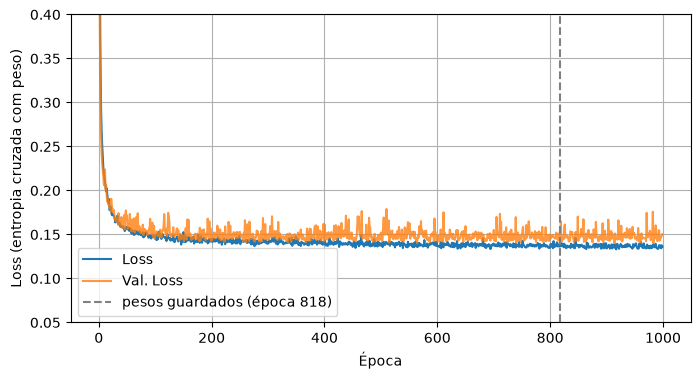

In [12]:
# Curvas da semente 0
melhor_epoca, losses, val_losses = curvas[0]

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.plot(val_losses, alpha=0.8)
plt.axvline(melhor_epoca - 1, color="gray", linestyle="--")
plt.legend(["Loss", "Val. Loss", f"pesos guardados (época {melhor_epoca})"])
plt.xlabel("Época")
plt.ylabel("Loss (entropia cruzada com peso)")
plt.ylim(0.05, 0.4)
plt.grid(True)
plt.show()

As duas curvas andam juntas: com 8 neurônios não há sobreajuste visível. Com
redes maiores (64 neurônios), a perda de treino continua caindo enquanto a de
validação sobe (notebook `07`); guardar os pesos do mínimo da validação protege
contra isso.

---
# (iii) Avaliação do modelo treinado

## Métricas

Implementadas a partir da **matriz de confusão** (Slides_6), com linha = espécie
prevista e coluna = espécie verdadeira. Para cada espécie, tratando-a como positiva:
**sensibilidade** (das gravações dela, quantas o modelo acha) e **precisão**
(quando o modelo diz que é ela, quantas vezes acerta).

- **Acurácia balanceada** (métrica principal): média das sensibilidades das 8
  espécies. Cada espécie pesa igual; com 19:1, a acurácia comum seria dominada por
  *Myotis lavali*.
- **F1 macro**: média do F1 de cada espécie (Grandini et al., 2020).
- **Acurácia**: fração de acertos, para referência.

In [13]:
# Espécie prevista: a de maior probabilidade na saída
def prever(model, X):
    model.eval()
    with torch.no_grad():
        y = model(X)
        # a softmax transforma a saída em probabilidades
        prob = torch.softmax(y, dim=1)
        _, predito = torch.max(prob, 1)
    return predito.numpy()


# Matriz de confusão: linha = espécie prevista, coluna = espécie verdadeira
def matriz_confusao(d, predito):
    M = np.zeros((N_classes, N_classes), dtype=int)
    for i in range(len(d)):
        M[predito[i], d[i]] += 1
    return M


# Medidas de desempenho calculadas a partir da matriz de confusão
def medidas(M):
    sens = np.zeros(N_classes)
    prec = np.zeros(N_classes)
    f1 = np.zeros(N_classes)
    for k in range(N_classes):
        VP = M[k, k]
        # sensibilidade: das gravações da espécie k, quantas foram achadas
        sens[k] = VP / M[:, k].sum()
        # precisão: das vezes em que o modelo disse k, quantas estavam certas
        if M[k, :].sum() > 0:
            prec[k] = VP / M[k, :].sum()
        if prec[k] + sens[k] > 0:
            f1[k] = 2 * prec[k] * sens[k] / (prec[k] + sens[k])
    acuracia_balanceada = sens.mean()
    f1_macro = f1.mean()
    acuracia = np.trace(M) / M.sum()
    return acuracia_balanceada, f1_macro, acuracia, sens, prec

## Referências para comparar

- **Modelo linear**: regressão softmax (uma camada `Linear(5, 8)`, sem camada
  oculta), treinado nas **mesmas condições** da MLP: mesma função custo com peso, Adam
  com passo 0,01, mini-batch 64, até 1000 épocas e pesos do mínimo da validação. Essa
  configuração foi a melhor na validação entre cinco opções de otimizador e passo
  (notebook `11`). A única diferença para a MLP é a camada oculta.
- **Regra de FME da chave de identificação**: sem aprendizado; cada gravação recebe
  a espécie cuja FME típica, segundo a chave dos especialistas, está mais perto da
  FME medida. Faixas da chave convertidas em números pelo ponto médio.

In [14]:
# Modelo linear: a mesma rede sem a camada oculta
class ModelLinear(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # Entrada com 5 medidas, conectada direto aos 8 neurônios de saída
            nn.Linear(N_entradas, N_classes),
        )

    def forward(self, x):
        output = self.model(x)
        return output

In [15]:
# Mesmo treino da MLP: mesma função custo, otimizador, passo, mini-batch, épocas e sementes
modelos_linear = []

for semente in sementes:
    torch.manual_seed(semente)
    model = ModelLinear()
    optimizer = torch.optim.Adam(model.parameters(), lr=eta)

    torch.manual_seed(semente)
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=Nb, shuffle=True)

    melhor_val_loss = float("inf")
    melhores_pesos = None
    melhor_epoca = -1

    for epoch in range(Ne):
        model.train()
        for X, d in train_loader:
            model.zero_grad()
            y = model(X)
            loss = loss_function(y, d)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            y_val = model(Xva)
            val_loss = loss_function(y_val, dva)

        if val_loss.item() < melhor_val_loss:
            melhor_val_loss = val_loss.item()
            melhores_pesos = copy.deepcopy(model.state_dict())
            melhor_epoca = epoch + 1

    model.load_state_dict(melhores_pesos)
    modelos_linear.append(model)
    print(f"semente {semente}: pesos da época {melhor_epoca} (perda de validação {melhor_val_loss:.3f})")

semente 0: pesos da época 581 (perda de validação 0.355)


semente 1: pesos da época 565 (perda de validação 0.355)


semente 2: pesos da época 681 (perda de validação 0.355)


In [16]:
# Regra de FME da chave de identificação: FME típica de cada espécie (ponto médio da faixa)
FME_CHAVE = {"Eumops_sp": 18.0, "Molossus_currentium": 30.0, "Molossus_molossus": 34.0,
             "Neoeptesicus_furinalis": 39.0, "Lasiurus_blossevillii": 46.0,
             "Molossops_temminckii": 50.0, "Myotis_lavali": 50.5, "Myotis_nigricans": 53.5}
centros = np.array([FME_CHAVE[e] for e in ESPECIES])


# Cada gravação recebe a espécie cuja FME típica está mais perto da FME medida
def regra_chave(pos):
    fme = X_bruto[pos, 3]
    predito = np.zeros(len(pos), dtype=int)
    for i in range(len(pos)):
        predito[i] = np.argmin(np.abs(fme[i] - centros))
    return predito

## Resultado no conjunto de teste

Uso único do teste (2.011 gravações). A validação aparece ao lado para comparar.

In [17]:
nomes_medidas = ["acurácia balanceada", "F1 macro", "acurácia"]

for nome, modelos in [("MLP", modelos_mlp), ("modelo linear", modelos_linear)]:
    for conjunto, X, d in [("validação", Xva, dva), ("teste", Xte, dte)]:
        # uma linha por semente, uma coluna por medida
        valores = np.zeros((len(modelos), 3))
        for s in range(len(modelos)):
            M = matriz_confusao(d.numpy(), prever(modelos[s], X))
            valores[s, :] = medidas(M)[0:3]
        print(f"{nome} - {conjunto}")
        for j in range(3):
            print(f"   {nomes_medidas[j]}: {valores[:, j].mean():.3f} ± {valores[:, j].std():.3f}")

for conjunto, pos, d in [("validação", pos_va, dva), ("teste", pos_te, dte)]:
    M = matriz_confusao(d.numpy(), regra_chave(pos))
    valores = medidas(M)[0:3]
    print(f"regra da chave - {conjunto}")
    for j in range(3):
        print(f"   {nomes_medidas[j]}: {valores[j]:.3f}")

MLP - validação
   acurácia balanceada: 0.966 ± 0.002
   F1 macro: 0.922 ± 0.004
   acurácia: 0.950 ± 0.003
MLP - teste
   acurácia balanceada: 0.959 ± 0.000
   F1 macro: 0.926 ± 0.005
   acurácia: 0.955 ± 0.004
modelo linear - validação
   acurácia balanceada: 0.953 ± 0.001
   F1 macro: 0.901 ± 0.002
   acurácia: 0.935 ± 0.001
modelo linear - teste
   acurácia balanceada: 0.942 ± 0.001
   F1 macro: 0.901 ± 0.001
   acurácia: 0.937 ± 0.001
regra da chave - validação
   acurácia balanceada: 0.694
   F1 macro: 0.612
   acurácia: 0.545
regra da chave - teste
   acurácia balanceada: 0.697
   F1 macro: 0.623
   acurácia: 0.553


In [18]:
# Matriz de confusão da MLP no teste, uma por semente
matrizes = [matriz_confusao(dte.numpy(), prever(model, Xte)) for model in modelos_mlp]

# Sensibilidade e precisão de cada espécie (média das 3 sementes)
sens_media = np.mean([medidas(M)[3] for M in matrizes], axis=0)
prec_media = np.mean([medidas(M)[4] for M in matrizes], axis=0)
n_teste = np.bincount(dte.numpy(), minlength=N_classes)

print(f"{'espécie':24s} {'gravações no teste':>19s} {'sensibilidade':>14s} {'precisão':>9s}")
for k in range(N_classes):
    print(f"{ESPECIES[k]:24s} {n_teste[k]:19d} {sens_media[k]:14.3f} {prec_media[k]:9.3f}")

espécie                   gravações no teste  sensibilidade  precisão
Myotis_lavali                           1092          0.956     0.996
Molossus_molossus                        247          0.928     0.979
Lasiurus_blossevillii                    163          0.957     0.921
Neoeptesicus_furinalis                   152          0.936     0.936
Eumops_sp                                109          0.985     0.964
Molossus_currentium                      108          0.963     0.897
Molossops_temminckii                      83          0.996     0.914
Myotis_nigricans                          57          0.953     0.613


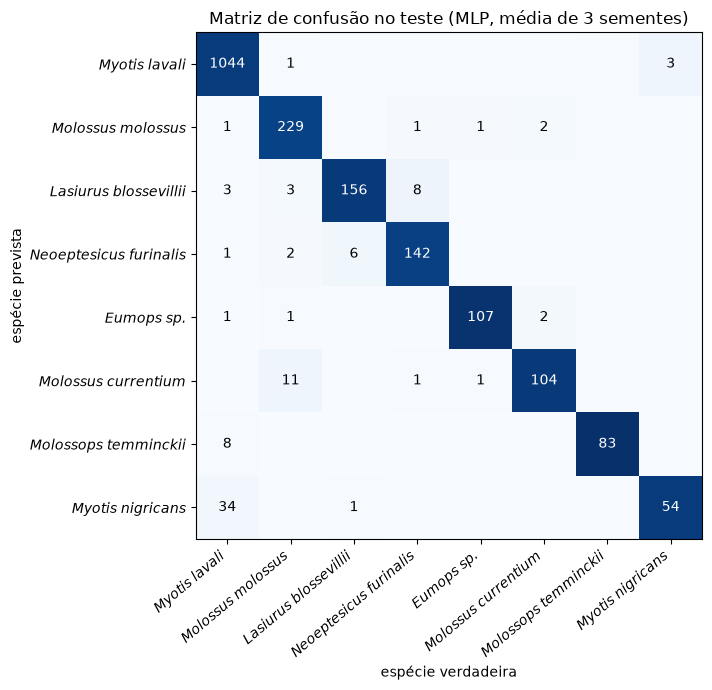

In [19]:
# Matriz de confusão média das 3 sementes
M = np.mean(matrizes, axis=0)
# fração em relação ao total de cada espécie verdadeira (coluna), usada na cor
frac = M / M.sum(axis=0, keepdims=True)
nomes = [e.replace("_", " ").replace(" sp", " sp.") for e in ESPECIES]

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
for i in range(N_classes):
    for j in range(N_classes):
        if M[i, j] >= 0.5:
            cor = "white" if frac[i, j] > 0.5 else "black"
            ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=10, color=cor)
ax.set_xticks(range(N_classes), nomes, rotation=40, ha="right", style="italic")
ax.set_yticks(range(N_classes), nomes, style="italic")
ax.set_xlabel("espécie verdadeira")
ax.set_ylabel("espécie prevista")
ax.set_title("Matriz de confusão no teste (MLP, média de 3 sementes)")
fig.tight_layout()
plt.show()

## Conclusões

- A MLP chega a **acurácia balanceada de 0,959 no teste** (0,966 na validação),
  contra 0,942 do modelo linear treinado nas mesmas condições e 0,697 da regra de FME
  da chave de identificação. A camada oculta reduz o erro em cerca de 30% (4,1% contra 5,8%).
- Todas as espécies são reconhecidas com sensibilidade acima de 0,92. O ponto fraco
  é a **precisão de *Myotis nigricans*** (≈0,61): gravações de *M. lavali*, do mesmo
  gênero e com faixas de frequência vizinhas, são chamadas de *M. nigricans*. É o
  custo do peso por classe, escolhido para não perder a espécie rara.
- Os erros restantes se concentram em pares próximos: *Molossus molossus* ×
  *M. currentium* e *Neoeptesicus furinalis* × *Lasiurus blossevillii*.

**Limitações.** O rótulo é a identificação acústica feita por especialistas (sem
captura), então a métrica mede concordância com eles. As medidas foram extraídas
manualmente do sonograma: a rede não parte do áudio. O modelo conhece só estas 8
espécies, de uma região e de um tipo de gravador. As checagens feitas nos
notebooks de trabalho (rótulos embaralhados, validação cruzada por local, divisão por
noite) e a validação externa em gravações coletadas depois (acurácia balanceada de 0,957
em 946 gravações de noites novas, média das 3 sementes) estão descritas no artigo. O artigo
traz também a análise das entradas feita após a apresentação: três das cinco medidas
(Fmin, Fmax e FME) dão o mesmo resultado (notebook `12` do repositório).